# Dice by cell density 

The paper's quartile table groups test images by the Dice of FS UNeXt itself, which (i) is not a density measure
and (ii) creates regression to the mean. Here the 265 test images are grouped by **density indices computed on the
ground-truth mask only**, so the grouping does not depend on any model:

| Index | Definition (640x480 ground-truth mask) |
|---|---|
| `cell_pct` | percentage of cell pixels |
| `n_cells` | number of 8-connected cell components |
| `clump_pct` | percentage of the cell area lying in components larger than `CLUMP_FACTOR` x the median component area of the image (touching / clumped cells); components smaller than `MIN_AREA` px are ignored for the median |

For each index and label ratio: quartile groups with the number of images, mean Dice of FS UNeXt and DACL,
mean and median difference, a bootstrap 95% CI of the mean difference, the paired Wilcoxon p-value (and Holm
correction over the 4 groups), the number of images where DACL is better, and Spearman's rho between the index and
the difference. Other methods (CPS, FS Swin-Unet) are shown as differences to FS UNeXt for context.

A last section repeats the difficulty grouping of the paper with a **control for regression to the mean**:
images are grouped by FS UNeXt Dice at the *other* label ratio (an independent run), not at the evaluated one.

**Inputs:** the per-image results of the main experiments (`test_per_image.csv`, e.g. the repository's `results/`)
and the ground-truth masks (prepared 640x480 masks of any training notebook, or the raw dataset). CPU only.

## 1. Configuration

In [1]:
from pathlib import Path


class CFG:
    # Folders searched (recursively) for <run>/test_per_image.csv, e.g. the repository's results/ folder.
    # On Kaggle the whole /kaggle/input is searched, so the mount path of the dataset does not matter.
    RESULT_DIRS = ["/kaggle/input", "../results", "results"]
    # Prepared 640x480 masks (data/processed/masks of any training notebook). If missing, they are prepared
    # from RAW_DIR with exactly the code of the training notebooks (needs OpenCV).
    PROCESSED_DIR = "/kaggle/working/data/processed"
    RAW_DIR = "/kaggle/input/bloodcell/bloodcell_dataset"
    IMAGE_SUBDIR = "Original"
    MASK_SUBDIR = "Mask"
    WORK_DIR = "/kaggle/working" if Path("/kaggle/working").exists() else "work_exp4"
    PREP_SIZE = (640, 480)
    MASK_THRESHOLD = 127

    LABELED_RATIOS = [5, 10]
    SEED = 2026
    REFERENCE = "unext"           # FS UNeXt
    TARGET = "dacl"
    OTHERS = ["cps", "swin_unet"]  # shown as differences to the reference
    CLUMP_FACTOR = 2.0
    MIN_AREA = 30
    N_BOOT = 2000

In [2]:
import re
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from scipy.stats import spearmanr, wilcoxon

OUT_DIR = Path(CFG.WORK_DIR) / "exp4_density"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def find_csv(run):
    for root in CFG.RESULT_DIRS:
        if Path(root).exists():
            for f in sorted(Path(root).glob(f"**/{run}/test_per_image.csv")):
                return f
    raise FileNotFoundError(f"{run}/test_per_image.csv not found in {CFG.RESULT_DIRS}")


def dice(run, ratio):
    df = pd.read_csv(find_csv(f"{run}_{ratio}p_s{CFG.SEED}"), dtype={"name": str})
    return df.set_index("name")["dsc"] * 100


test_names = sorted(dice(CFG.REFERENCE, CFG.LABELED_RATIOS[0]).index)
print(len(test_names), "test images")

265 test images


## 2. Density indices of the test images

In [3]:
def prepared_mask_dir():
    """Folder with the 640x480 masks named like the result files (0000.png, ...)."""
    d = Path(CFG.PROCESSED_DIR) / "masks"
    if d.exists() and all((d / f"{n}.png").exists() for n in test_names):
        return d
    # Same preparation as the training notebooks: pairs sorted by name, resized with nearest neighbour,
    # thresholded at MASK_THRESHOLD, saved as 0000.png, 0001.png, ...
    import cv2
    exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    suffix = re.compile(r"[ _\-]?(mask|masks|gt|label|labels|image|images|img|original)$", re.I)
    index = lambda folder: {suffix.sub("", p.stem).strip().lower(): p
                            for p in sorted(folder.rglob("*")) if p.suffix.lower() in exts}
    raw = Path(CFG.RAW_DIR)
    if not ((raw / CFG.IMAGE_SUBDIR).is_dir() and (raw / CFG.MASK_SUBDIR).is_dir()):
        # same fallback as the training notebooks: search /kaggle/input for Original/ + Mask/
        cands = [c.parent for c in Path("/kaggle/input").rglob(CFG.MASK_SUBDIR)
                 if c.is_dir() and (c.parent / CFG.IMAGE_SUBDIR).is_dir()] if Path("/kaggle/input").exists() else []
        if not cands:
            raise FileNotFoundError(f"No folder with {CFG.IMAGE_SUBDIR}/ and {CFG.MASK_SUBDIR}/ found - check CFG.RAW_DIR.")
        raw = cands[0]
        print("CFG.RAW_DIR not found - using", raw)
    images, masks = index(raw / CFG.IMAGE_SUBDIR), index(raw / CFG.MASK_SUBDIR)
    keys = sorted(set(images) & set(masks))
    print(f"raw dataset: {raw} | {len(images)} images, {len(masks)} masks -> {len(keys)} pairs")
    if len(keys) != 1328:
        raise RuntimeError(f"Expected 1328 image/mask pairs in {raw}, found {len(keys)} - check CFG.RAW_DIR "
                           f"(folder that contains {CFG.IMAGE_SUBDIR}/ and {CFG.MASK_SUBDIR}/).")
    d = Path(CFG.WORK_DIR) / "masks"
    d.mkdir(parents=True, exist_ok=True)
    for i, k in enumerate(keys):
        m = cv2.resize(cv2.imread(str(masks[k]), cv2.IMREAD_GRAYSCALE), CFG.PREP_SIZE, interpolation=cv2.INTER_NEAREST)
        cv2.imwrite(str(d / f"{i:04d}.png"), np.where(m > CFG.MASK_THRESHOLD, 255, 0).astype(np.uint8))
    print(f"prepared {len(keys)} masks in {d}")
    return d


def density_indices(mask):
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    areas = np.bincount(lab.ravel())[1:]
    big = areas[areas >= CFG.MIN_AREA]
    med = np.median(big) if len(big) else np.nan
    clump = areas[areas > CFG.CLUMP_FACTOR * med].sum() if len(big) else 0
    return {"cell_pct": 100 * mask.mean(), "n_cells": n, "clump_pct": 100 * clump / max(mask.sum(), 1)}


mask_dir = prepared_mask_dir()
dens = pd.DataFrame({n: density_indices(np.asarray(Image.open(mask_dir / f"{n}.png").convert("L")) > 127)
                     for n in test_names}).T
dens.index.name = "name"
dens.to_csv(OUT_DIR / "density_indices.csv")
display(dens.describe().round(2))

CFG.RAW_DIR not found - using /kaggle/input/datasets/vuduybinh1/bloodcell/bloodcell_dataset
raw dataset: /kaggle/input/datasets/vuduybinh1/bloodcell/bloodcell_dataset | 1328 images, 1328 masks -> 1328 pairs
prepared 1328 masks in /kaggle/working/masks


,cell_pct,n_cells,clump_pct
count,265.00,265.00,265.00
mean,29.82,59.54,16.86
std,11.31,22.95,18.35
min,4.80,10.00,0.00
25%,22.14,44.00,4.17
50%,28.36,57.00,11.51
75%,35.00,72.00,22.08
max,71.59,140.00,87.49


## Dice difference by density group

Groups are quartiles of each index (edges = 25/50/75th percentiles; a value equal to an edge goes to the upper
group, so tied integer indices such as `n_cells` can give unequal group sizes - `n` is reported); p-values are paired Wilcoxon tests within a group, with a Holm
correction over the 4 groups of one index. The bootstrap CI resamples the images of a group (`N_BOOT` times).

In [4]:
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


def boot_ci(d, rng):
    m = rng.choice(d, size=(CFG.N_BOOT, len(d)), replace=True).mean(1)
    return np.percentile(m, [2.5, 97.5])


rng = np.random.default_rng(0)
rows, rho_rows = [], []
for ratio in CFG.LABELED_RATIOS:
    ref, tgt = dice(CFG.REFERENCE, ratio).loc[test_names], dice(CFG.TARGET, ratio).loc[test_names]
    others = {o: dice(o, ratio).loc[test_names] for o in CFG.OTHERS}
    diff = tgt - ref
    for idx in ["cell_pct", "n_cells", "clump_pct"]:
        x = dens.loc[test_names, idx].astype(float)
        # quartile edges of the index; a value equal to an edge goes to the upper group (as in the paper)
        grp = np.digitize(x.values, np.quantile(x.values, [0.25, 0.5, 0.75]))
        block = []
        for gi, g in enumerate(["Q1 (low)", "Q2", "Q3", "Q4 (high)"]):
            k = grp == gi
            if not k.any():
                continue
            d = diff.values[k]
            lo, hi = boot_ci(d, rng)
            block.append({"ratio": ratio, "index": idx, "group": g, "n": int(k.sum()),
                          "range": f"{x[k].min():.1f} - {x[k].max():.1f}",
                          "FS": ref.values[k].mean(), "DACL": tgt.values[k].mean(),
                          "diff_mean": d.mean(), "diff_median": np.median(d), "ci_low": lo, "ci_high": hi,
                          "p": wilcoxon(tgt.values[k], ref.values[k]).pvalue, "dacl_better": int((d > 0).sum()),
                          **{f"{o}-FS": (others[o].values[k] - ref.values[k]).mean() for o in CFG.OTHERS}})
        for r, padj in zip(block, holm([r["p"] for r in block])):
            r["p_holm"] = padj
        rows += block
        rho, p = spearmanr(x, diff)
        rho_rows.append({"ratio": ratio, "index": idx, "spearman_rho": rho, "p": p})
groups = pd.DataFrame(rows)
groups.to_csv(OUT_DIR / "density_groups.csv", index=False)
display(groups.round(3))
display(pd.DataFrame(rho_rows).round(3))

,ratio,index,group,n,range,FS,DACL,diff_mean,diff_median,ci_low,ci_high,p,dacl_better,cps-FS,swin_unet-FS,p_holm
0,5,cell_pct,Q1 (low),66,4.8 - 22.1,93.965,94.049,0.084,-0.113,-0.318,0.460,0.992,27,-0.481,0.357,1.000
1,5,cell_pct,Q2,66,22.1 - 28.3,94.536,94.490,-0.046,-0.144,-0.266,0.222,0.002,17,-0.296,0.433,0.007
2,5,cell_pct,Q3,66,28.4 - 34.6,94.211,94.714,0.503,-0.198,0.020,1.187,0.373,23,0.033,0.775,1.000
3,5,cell_pct,Q4 (high),67,35.0 - 71.6,93.905,94.279,0.374,-0.076,-0.083,1.182,0.960,31,0.049,0.705,1.000
4,5,n_cells,Q1 (low),66,10.0 - 43.0,93.725,94.510,0.785,0.003,0.143,1.691,0.141,33,0.008,0.825,0.358
5,5,n_cells,Q2,64,44.0 - 56.0,93.846,94.110,0.264,-0.159,-0.162,0.827,0.119,19,-0.074,0.617,0.358
6,5,n_cells,Q3,67,57.0 - 71.0,94.234,94.232,-0.002,-0.191,-0.381,0.378,0.200,23,-0.344,0.441,0.358
7,5,n_cells,Q4 (high),68,72.0 - 140.0,94.779,94.664,-0.115,-0.129,-0.221,0.005,0.007,23,-0.274,0.398,0.029
8,5,clump_pct,Q1 (low),66,0.0 - 4.2,94.925,94.986,0.061,-0.154,-0.165,0.328,0.231,21,-0.310,0.392,0.536
9,5,clump_pct,Q2,66,4.2 - 11.4,94.675,94.632,-0.043,-0.094,-0.425,0.290,0.179,24,-0.377,0.450,0.536


,ratio,index,spearman_rho,p
0,5,cell_pct,0.006,0.926
1,5,n_cells,-0.167,0.006
2,5,clump_pct,0.100,0.103
3,10,cell_pct,-0.113,0.067
4,10,n_cells,-0.134,0.030
5,10,clump_pct,0.065,0.291


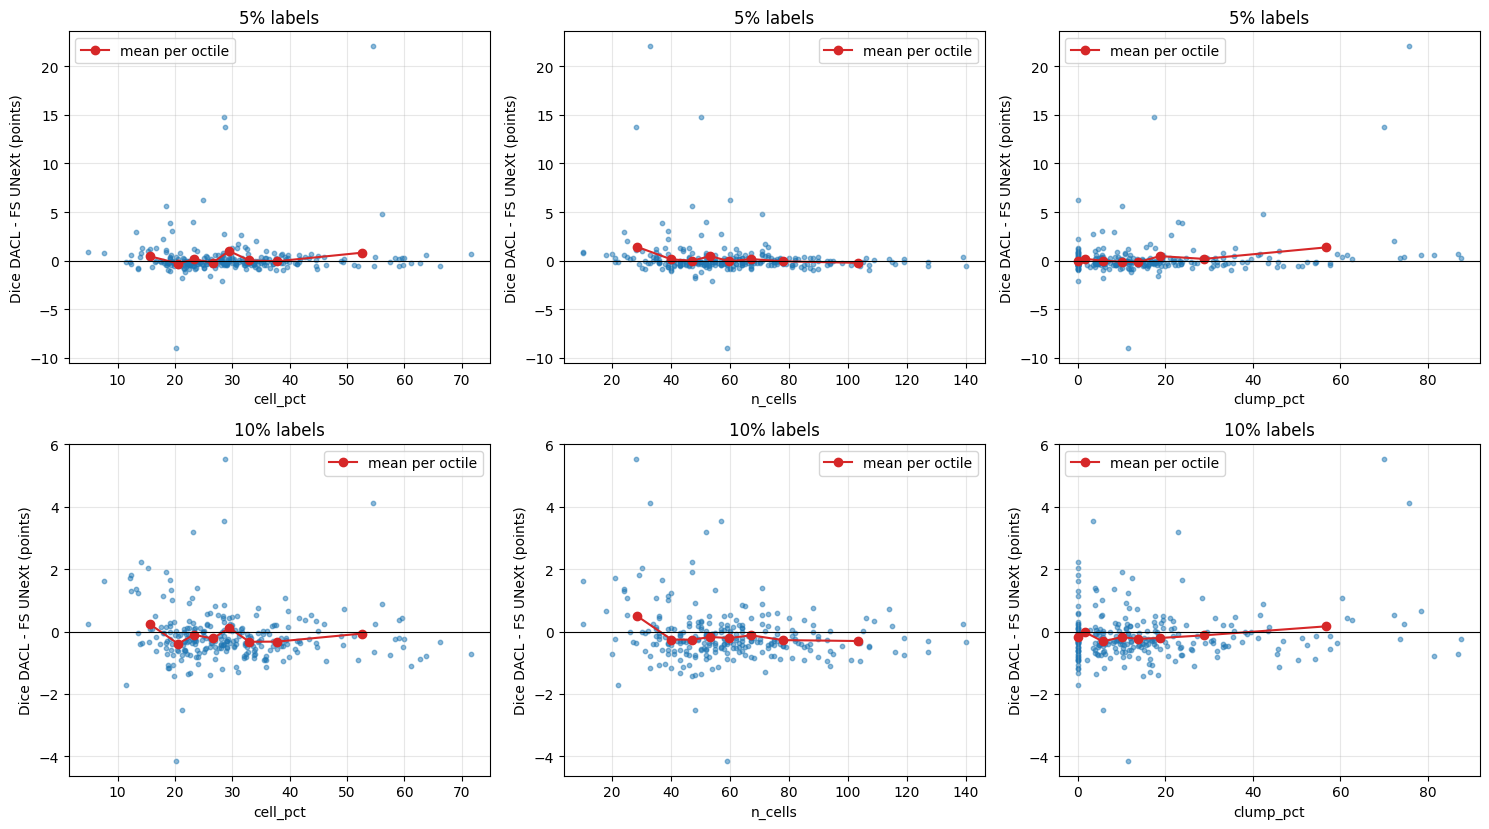

In [5]:
fig, axes = plt.subplots(len(CFG.LABELED_RATIOS), 3, figsize=(15, 4.2 * len(CFG.LABELED_RATIOS)), squeeze=False)
for i, ratio in enumerate(CFG.LABELED_RATIOS):
    diff = (dice(CFG.TARGET, ratio) - dice(CFG.REFERENCE, ratio)).loc[test_names]
    for j, idx in enumerate(["cell_pct", "n_cells", "clump_pct"]):
        ax, x = axes[i, j], dens.loc[test_names, idx].astype(float)
        ax.scatter(x, diff, s=10, alpha=.5)
        bins = pd.qcut(x.rank(method="first"), 8)
        b = pd.DataFrame({"x": x, "d": diff}).groupby(bins, observed=True).mean()
        ax.plot(b["x"], b["d"], "o-", color="C3", label="mean per octile")
        ax.axhline(0, color="k", lw=.8)
        ax.set(xlabel=idx, ylabel="Dice DACL - FS UNeXt (points)", title=f"{ratio}% labels")
        ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "density_scatter.png", dpi=150); plt.show()

## Difficulty groups with a control for regression to the mean

The paper groups images by the Dice of FS UNeXt at the **same** ratio as the evaluated runs, so images where FS
UNeXt was unlucky land in Q1 and any other model looks better there. Grouping by FS UNeXt at the **other** ratio
(an independent training run) keeps the "hard image" meaning but removes most of that selection effect.

In [6]:
rows = []
for ratio in CFG.LABELED_RATIOS:
    other = [r for r in CFG.LABELED_RATIOS if r != ratio]
    if not other:
        continue
    ref, tgt = dice(CFG.REFERENCE, ratio).loc[test_names], dice(CFG.TARGET, ratio).loc[test_names]
    for basis, score in [("same run (paper)", ref), (f"FS UNeXt at {other[0]}%", dice(CFG.REFERENCE, other[0]).loc[test_names])]:
        grp = pd.qcut(score.rank(method="first"), 4, labels=["Q1 (hardest)", "Q2", "Q3", "Q4 (easiest)"])
        for g in grp.cat.categories:
            k = (grp == g).values
            rows.append({"ratio": ratio, "grouping": basis, "group": g, "n": int(k.sum()),
                         "DACL-FS": (tgt - ref).values[k].mean(),
                         **{f"{o}-FS": (dice(o, ratio).loc[test_names] - ref).values[k].mean() for o in CFG.OTHERS}})
rtm = pd.DataFrame(rows)
rtm.to_csv(OUT_DIR / "difficulty_rtm_control.csv", index=False)
display(rtm.round(2))

,ratio,grouping,group,n,DACL-FS,cps-FS,swin_unet-FS
0,5,same run (paper),Q1 (hardest),67,1.37,0.28,1.27
1,5,same run (paper),Q2,66,0.02,-0.22,0.39
2,5,same run (paper),Q3,66,-0.17,-0.37,0.40
3,5,same run (paper),Q4 (easiest),66,-0.32,-0.39,0.21
4,5,FS UNeXt at 10%,Q1 (hardest),67,1.29,0.29,1.19
5,5,FS UNeXt at 10%,Q2,66,-0.09,-0.32,0.30
6,5,FS UNeXt at 10%,Q3,66,-0.04,-0.32,0.44
7,5,FS UNeXt at 10%,Q4 (easiest),66,-0.26,-0.35,0.32
8,10,same run (paper),Q1 (hardest),67,0.34,-1.02,0.90
9,10,same run (paper),Q2,66,-0.13,-1.31,0.30
